# 02 · Red peatonal con pendiente: ¿cuánto cuesta caminar en La Paz y El Alto?

**Pregunta:** ¿cómo es la red por la que la gente camina hasta el teleférico y cuánto cambia el tiempo
de caminata cuando se considera la pendiente, en una ciudad que va de ~3.000 a ~4.100 m?

**Fuentes** (ver `docs/plan.md` §4):
- Red peatonal de **OpenStreetMap** (`network_type="walk"` de OSMnx), en `teleferico.ingest.osm`.
- **Copernicus GLO-30** (DEM de 30 m) para la elevación, en `teleferico.ingest.dem`.
- Censo 2024 (manzanos) y límites de OSM, para normalizar la red por población y área.

**Método** (`teleferico.access`):
- Velocidad de **Tobler**, `v = 6·exp(−3.5·|s + 0.05|)` km/h, **direccional**: `s` es la pendiente en
  el sentido de la marcha, así que subir y bajar la misma calle cuestan distinto. La caminata "plana" usa
  la misma función con `s = 0` (≈ 5,04 km/h), para que la única diferencia entre ambas sea la pendiente.
- La pendiente se mide **a lo largo de la calle**, no solo entre sus extremos: se muestrea el DEM cada
  30 m sobre la geometría de cada arista y el tiempo es la suma de los tramos.

In [1]:
import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from shapely.geometry import Polygon

from teleferico import access as ac
from teleferico import viz
from teleferico.config import CRS_METRIC, CRS_WGS84, PROCESSED

viz.estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

nod = ac.nodos()
a = ac.aristas_tiempo().to_crs(CRS_METRIC)
lim = gpd.read_parquet(PROCESSED / "limites.parquet").to_crs(CRS_METRIC)
mun = lim.query("nivel == 'municipio'")
est = gpd.read_parquet(PROCESSED / "red" / "estaciones.parquet").to_crs(CRS_METRIC)
lineas = gpd.read_parquet(PROCESSED / "red" / "lineas.parquet").to_crs(CRS_METRIC)
mz = gpd.read_parquet(PROCESSED / "censo" / "manzanos.parquet",
                      columns=["municipio", "personas", "area_m2", "geometry"])
bounds = mz.to_crs(CRS_METRIC).total_bounds + np.array([-800, -800, 800, 800])

# El grafo peatonal tiene cada calle en los dos sentidos: para longitudes se usa un solo sentido.
uno = a[a["u"] < a["v"]].copy()
medio = uno.geometry.interpolate(0.5, normalized=True)
uno["municipio"] = (gpd.GeoDataFrame(geometry=medio, crs=CRS_METRIC)
                    .sjoin(mun[["nombre", "geometry"]], how="left", predicate="within")
                    .groupby(level=0)["nombre"].first().fillna("Fuera (margen)"))
# Pendiente media absoluta a lo largo del perfil (no la neta entre extremos).
uno["pend_perfil"] = (uno["subida_m"] + uno["bajada_m"]) / uno["length"]
print(f"{len(nod):,} nodos · {len(a):,} aristas dirigidas · {uno['length'].sum() / 1000:,.0f} km de calles")

89,564 nodos · 269,006 aristas dirigidas · 8,523 km de calles


## 1. La red: ¿qué tan completa es OSM en cada municipio?

El plan identifica un riesgo: OSM podría tener El Alto peor mapeado que La Paz (calles sin mapear o
senderos informales). Se compara la longitud de la red con la población y con el área de los manzanos.

In [2]:
def tipo_via(h: str) -> str:
    if "steps" in h:
        return "Gradas"
    if any(k in h for k in ("footway", "path", "pedestrian", "living_street")):
        return "Peatonal"
    if any(k in h for k in ("trunk", "primary", "secondary", "tertiary")):
        return "Avenida"
    if any(k in h for k in ("residential", "unclassified")):
        return "Calle residencial"
    return "Servicio y otros"

uno["tipo"] = uno["highway"].map(tipo_via)
mz_mun = mz.groupby("municipio").agg(personas=("personas", "sum"), area_km2=("area_m2", lambda s: s.sum() / 1e6))
km = uno.groupby("municipio")["length"].sum() / 1000
red = mz_mun.assign(km_red=km).dropna()
red["m_red_por_hab"] = red["km_red"] * 1000 / red["personas"]
red["km_red_por_km2_manzanos"] = red["km_red"] / red["area_km2"]
mix = (uno.pivot_table(index="municipio", columns="tipo", values="length", aggfunc="sum")
       .pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100).loc[red.index])
pd.concat([red, mix.add_prefix("% ")], axis=1).T

municipio,El Alto,La Paz
personas,"885,210.00","750,225.00"
area_km2,119.93,62.19
km_red,"5,077.73","2,726.78"
m_red_por_hab,5.74,3.63
km_red_por_km2_manzanos,42.34,43.85
% Avenida,13.55,14.52
% Calle residencial,74.76,55.34
% Gradas,0.10,5.46
% Peatonal,3.69,15.97
% Servicio y otros,7.91,8.71


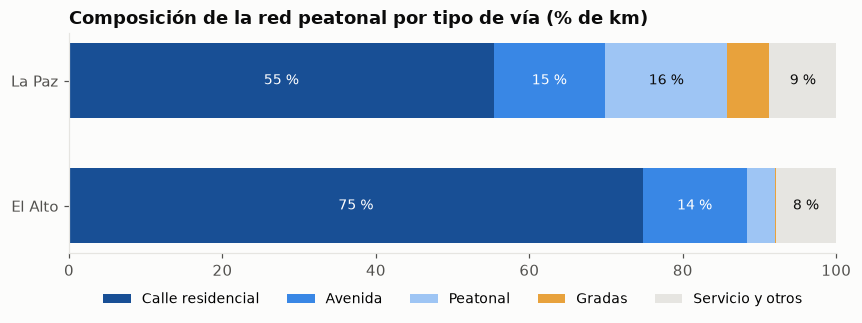

In [3]:
fig, ax = plt.subplots(figsize=(9, 2.6))
orden = ["Calle residencial", "Avenida", "Peatonal", "Gradas", "Servicio y otros"]
colores = dict(zip(orden, [viz.SECUENCIAL[5], viz.SECUENCIAL[3], viz.SECUENCIAL[1], "#e8a23c", viz.GRILLA]))
izq = np.zeros(len(mix))
for t in orden:
    ax.barh(mix.index, mix[t], left=izq, color=colores[t], label=t, height=0.6)
    for i, (x0, w) in enumerate(zip(izq, mix[t])):
        if w > 6:
            ax.text(x0 + w / 2, i, f"{w:.0f} %", ha="center", va="center", fontsize=9,
                    color="white" if t in orden[:2] else viz.TINTA)
    izq += mix[t].to_numpy()
ax.set_xlim(0, 100)
ax.grid(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
ax.set_title("Composición de la red peatonal por tipo de vía (% de km)")
viz.guardar(fig, "02_tipos_via")
plt.show()

**Lectura:**
- La red tiene ~8.500 km de calles: 5.078 km en El Alto y 2.727 km en La Paz.
- Por persona, El Alto tiene **más** red (5,7 m/hab frente a 3,6 m/hab) y, por km² de manzanos, las
  dos tienen casi la misma densidad (42 y 44 km/km²). **No hay señal de que OSM tenga El Alto peor
  mapeado**, al menos en longitud. Sí puede faltar algún sendero informal, y eso no se puede detectar así.
- La forma de caminar es distinta: en La Paz el 5,5 % de la red son **gradas** y el 16 % pasajes
  peatonales (escalinatas, sendas en ladera); en El Alto son el 0,1 % y el 3,7 %. El Alto es una
  cuadrícula de calles residenciales (75 %).

## 2. Elevación y pendiente

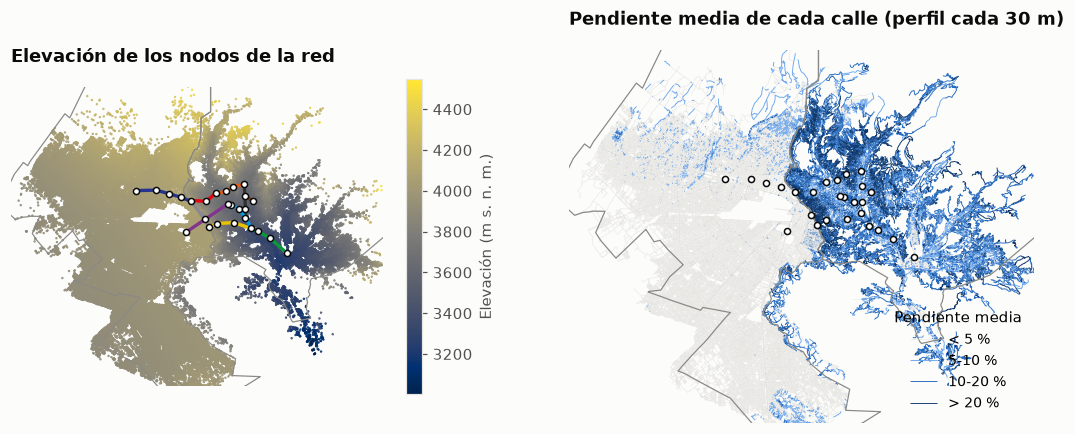

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2))
ax = axs[0]
sc = ax.scatter(nod.geometry.x, nod.geometry.y, c=nod["elevation"], s=0.3, cmap="cividis", rasterized=True)
viz.mapa_base(ax, mun, lineas, est, bounds)
fig.colorbar(sc, ax=ax, shrink=0.6, label="Elevación (m s. n. m.)")
ax.set_title("Elevación de los nodos de la red")

ax = axs[1]
cortes = [0, 0.05, 0.10, 0.20, np.inf]
etiquetas = ["< 5 %", "5-10 %", "10-20 %", "> 20 %"]
uno["clase_pend"] = pd.cut(uno["pend_perfil"], cortes, labels=etiquetas, right=False)
paleta = dict(zip(etiquetas, [viz.GRILLA, viz.SECUENCIAL[2], viz.SECUENCIAL[4], viz.SECUENCIAL[6]]))
for c in etiquetas:
    g = uno[uno["clase_pend"] == c]
    g.plot(ax=ax, color=paleta[c], lw=0.35 if c == etiquetas[0] else 0.6, rasterized=True, label=c)
viz.mapa_base(ax, mun, None, est, bounds)
ax.legend(title="Pendiente media", loc="lower right", fontsize=9, markerscale=3)
ax.set_title("Pendiente media de cada calle (perfil cada 30 m)")
viz.guardar(fig, "02_elevacion_pendiente")
plt.show()

In [5]:
km_clase = (uno.pivot_table(index="municipio", columns="clase_pend", values="length", aggfunc="sum", observed=False)
            .loc[["La Paz", "El Alto"]])
pct_clase = km_clase.div(km_clase.sum(axis=1), axis=0) * 100
pend_media = uno.groupby("municipio").apply(lambda g: np.average(g["pend_perfil"], weights=g["length"]) * 100,
                                             include_groups=False)
elev = (gpd.GeoDataFrame(nod, crs=CRS_METRIC).sjoin(mun[["nombre", "geometry"]], predicate="within")
        .groupby("nombre")["elevation"].describe(percentiles=[0.05, 0.5, 0.95]))
tabla_pend = pct_clase.round(1).assign(**{"pendiente media (%)": pend_media.round(1)})
tabla_pend.join(elev[["5%", "50%", "95%"]].add_prefix("elev. p").round(0))

,< 5 %,5-10 %,10-20 %,> 20 %,pendiente media (%),elev. p5%,elev. p50%,elev. p95%
municipio,,,,,,,,
La Paz,19.60,25.50,37.80,17.10,12.80,"3,285.00","3,632.00","4,071.00"
El Alto,93.90,5.20,0.70,0.20,1.90,"3,932.00","4,008.00","4,117.00"


**Lectura:**
- Son dos ciudades topográficamente opuestas. **El 94 % de las calles de El Alto tiene menos de 5 % de
  pendiente** (altiplano, ~3.930-4.120 m). En La Paz, **el 55 % de las calles supera el 10 %** y el
  17 % supera el 20 %, con ~790 m de desnivel entre el sur (p5 ≈ 3.285 m) y las laderas altas (p95 ≈ 4.070 m).
- Las estaciones de La Paz están en el fondo del valle y en las laderas bajas; las de El Alto, sobre el
  borde del altiplano (la Ceja). En La Paz, llegar a pie a una estación implica casi siempre subir o bajar.

## 3. La función de Tobler: subir cuesta mucho más que bajar

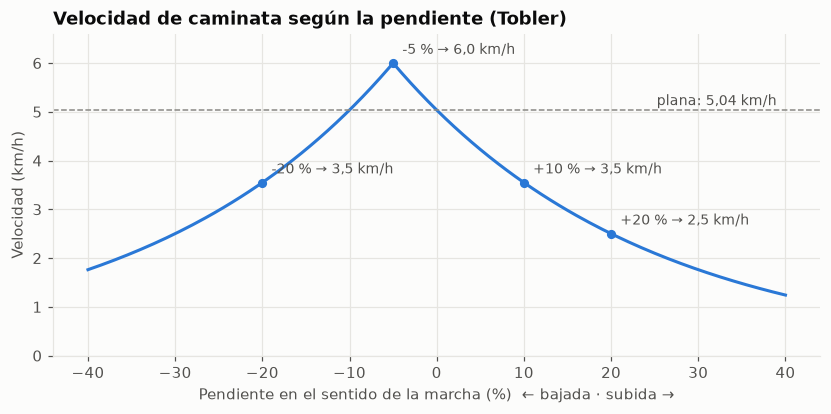

,km_h,min_por_100m,vs_plana
pendiente_%,,,
-30.00,2.50,2.40,2.01
-20.00,3.55,1.69,1.42
-10.00,5.04,1.19,1.00
-5.00,6.00,1.00,0.84
0.00,5.04,1.19,1.00
5.00,4.23,1.42,1.19
10.00,3.55,1.69,1.42
20.00,2.50,2.40,2.01
30.00,1.76,3.40,2.86


In [6]:
s = np.linspace(-0.4, 0.4, 161)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(s * 100, ac.tobler_kmh(s), color=viz.ACENTO)
ax.axhline(ac.V_PLANA_KMH, color=viz.TINTA_3, lw=1, ls="--")
ax.text(39, ac.V_PLANA_KMH + 0.1, f"plana: {viz.num(ac.V_PLANA_KMH, 2)} km/h", ha="right", fontsize=9, color=viz.TINTA_2)
for p in (-0.05, 0.10, 0.20, -0.20):
    v = float(ac.tobler_kmh(p))
    ax.plot(p * 100, v, "o", color=viz.ACENTO, ms=5)
    ax.annotate(f"{p * 100:+.0f} % → {viz.num(v, 1)} km/h", (p * 100, v), xytext=(6, 6),
                textcoords="offset points", fontsize=9, color=viz.TINTA_2)
ax.set_xlabel("Pendiente en el sentido de la marcha (%)  ← bajada · subida →")
ax.set_ylabel("Velocidad (km/h)")
ax.set_ylim(0, 6.6)
ax.set_title("Velocidad de caminata según la pendiente (Tobler)")
viz.guardar(fig, "02_tobler")
plt.show()

p = np.array([-0.30, -0.20, -0.10, -0.05, 0, 0.05, 0.10, 0.20, 0.30])
pd.DataFrame({
    "pendiente_%": p * 100,
    "km_h": ac.tobler_kmh(p),
    "min_por_100m": 100 / (ac.tobler_kmh(p) / 3.6) / 60,
    "vs_plana": ac.V_PLANA_KMH / ac.tobler_kmh(p),
}).set_index("pendiente_%")

## 4. Perfil a lo largo de la calle frente a la pendiente neta, y sensibilidad al DEM

Copernicus GLO-30 es un **modelo de superficie** (DSM): incluye techos y vegetación. Al muestrear cada
30 m, los techos aparecen como "baches" de pocos metros que se leen como subidas y bajadas falsas y
alargan el tiempo. Por eso el DEM se suaviza con un filtro gaussiano (σ = 1 píxel) antes de muestrear.
Se compara el tiempo total de la red con distintas decisiones:

In [7]:
def razon(perfil):
    return perfil["t_pendiente_s"].sum() / perfil["t_plana_s"].sum()

filas = [{"variante": "Pendiente neta entre extremos (sin perfil)", "razon": a["t_neta_s"].sum() / a["t_plana_s"].sum()}]
sigma0, paso0 = ac.SIGMA_SUAVIZADO_PX, ac.PASO_PERFIL_M
try:
    for sigma in (0.0, 1.0, 2.0):
        ac.SIGMA_SUAVIZADO_PX = sigma
        for paso in (15, 30, 60):
            pf = ac.perfil_aristas(a, paso_m=paso)
            filas.append({"variante": f"Perfil cada {paso} m, σ = {sigma:g} px", "razon": razon(pf),
                          "desnivel_vs_neto": (pf["subida_m"] + pf["bajada_m"]).sum() / (a["grade"].abs() * a["length"]).sum()})
finally:
    ac.SIGMA_SUAVIZADO_PX, ac.PASO_PERFIL_M = sigma0, paso0
sens = pd.DataFrame(filas).set_index("variante")
sens["sobrecosto_vs_plana_%"] = (sens["razon"] - 1) * 100
sens

,razon,desnivel_vs_neto,sobrecosto_vs_plana_%
variante,,,
Pendiente neta entre extremos (sin perfil),1.12,NaN,11.60
"Perfil cada 15 m, σ = 0 px",1.33,1.66,32.87
"Perfil cada 30 m, σ = 0 px",1.22,1.42,21.90
"Perfil cada 60 m, σ = 0 px",1.15,1.14,14.67
"Perfil cada 15 m, σ = 1 px",1.29,1.41,28.52
"Perfil cada 30 m, σ = 1 px",1.18,1.22,18.44
"Perfil cada 60 m, σ = 1 px",1.13,1.04,13.20
"Perfil cada 15 m, σ = 2 px",1.27,1.32,26.85
"Perfil cada 30 m, σ = 2 px",1.17,1.16,16.90


**Lectura:**
- Con la pendiente neta entre extremos, caminar toda la red cuesta un 11,6 % más que en llano. **Con
  el perfil cada 30 m y el DEM suavizado (σ = 1, la opción elegida) cuesta un 18,4 % más**: la pendiente
  neta subestima el costo porque ignora las calles que bajan y vuelven a subir.
- El resultado depende de cómo se trate el ruido del DSM: sin suavizar y con paso de 15 m el sobrecosto
  sube al 33 % (el desnivel acumulado es 1,66 veces el neto, en buena parte por techos). Con paso de
  60 m baja al 13-15 %. La opción elegida queda en el medio del rango y respeta la resolución del DEM
  (30 m). En el notebook 03 se mide cómo cambia la cobertura con estas variantes.

### Asimetría: el mismo tramo de subida y de bajada

En Tobler, para una misma pendiente mayor al 5 %, subir es siempre exp(0,35) ≈ **1,42 veces** más lento
que bajar. Pero bajar una pendiente fuerte también es más lento que caminar en llano (−20 % → 3,5 km/h).

In [8]:
pares = a[["u", "v", "length", "t_pendiente_s", "t_plana_s"]].merge(
    a[["u", "v", "t_pendiente_s"]], left_on=["u", "v"], right_on=["v", "u"], suffixes=("", "_vuelta"))
pares = pares[pares["u"] < pares["v"]].drop_duplicates(["u", "v"])
pares["lento"] = pares[["t_pendiente_s", "t_pendiente_s_vuelta"]].max(axis=1)
pares["rapido"] = pares[["t_pendiente_s", "t_pendiente_s_vuelta"]].min(axis=1)
pares["asimetria"] = pares["lento"] / pares["rapido"]
pares = pares.merge(uno[["u", "v", "municipio", "pend_perfil"]], on=["u", "v"])

res = pares.groupby("municipio").apply(lambda g: pd.Series({
    "km": g["length"].sum() / 1000,
    "subida_vs_plana": g["lento"].sum() / g["t_plana_s"].sum(),
    "bajada_vs_plana": g["rapido"].sum() / g["t_plana_s"].sum(),
    "% km con asimetría > 1,25×": g.loc[g["asimetria"] > 1.25, "length"].sum() / g["length"].sum() * 100,
}), include_groups=False).loc[["La Paz", "El Alto"]]
res

,km,subida_vs_plana,bajada_vs_plana,"% km con asimetría > 1,25×"
municipio,,,,
La Paz,"2,720.95",1.66,1.33,49.69
El Alto,"5,073.51",1.07,0.96,11.16


**Lectura:** en La Paz, recorrer las calles en el sentido de subida cuesta un **66 % más** que en llano y
en el de bajada un 33 % más. La mitad de los km (50 %) tiene una diferencia de más de 1,25× entre ir y
volver. En El Alto la diferencia es mínima (+7 % / −4 %).

## 5. ¿Dónde pesa la pendiente? Sobrecosto de caminar por hexágono

Para cada hexágono H3 (res. 9, ~0,1 km²) se compara el tiempo de recorrer todas sus calles en ambos
sentidos con pendiente frente a plano. Un valor de 1,3 significa caminar un 30 % más lento que en llano.

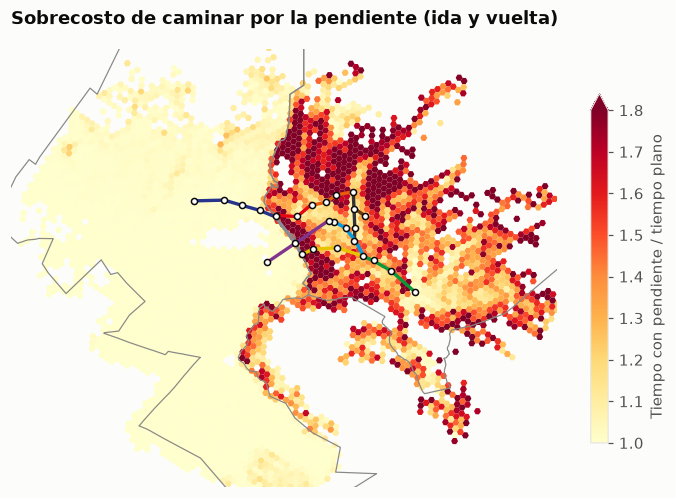

count   3,811.00
mean        1.22
std         0.33
min         1.00
10%         1.00
50%         1.02
90%         1.72
max         3.43
Name: sobrecosto, dtype: float64

In [9]:
a_ll = a.geometry.interpolate(0.5, normalized=True).to_crs(CRS_WGS84)
a["h3"] = [h3.latlng_to_cell(y, x, 9) for x, y in zip(a_ll.x, a_ll.y)]
hx = a.groupby("h3")[["t_pendiente_s", "t_plana_s", "length"]].sum()
hx = hx[hx["length"] > 300]  # hexágonos con poca red dan razones ruidosas
hx["sobrecosto"] = hx["t_pendiente_s"] / hx["t_plana_s"]
hx = gpd.GeoDataFrame(hx, geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in hx.index],
                      crs=CRS_WGS84).to_crs(CRS_METRIC)

fig, ax = plt.subplots(figsize=(8, 7.5))
hx.plot(ax=ax, column="sobrecosto", cmap="YlOrRd", vmin=1, vmax=1.8, legend=True,
        legend_kwds={"shrink": 0.55, "label": "Tiempo con pendiente / tiempo plano"})
viz.mapa_base(ax, mun, lineas, est, bounds)
ax.set_title("Sobrecosto de caminar por la pendiente (ida y vuelta)")
viz.guardar(fig, "02_sobrecosto_pendiente")
plt.show()
hx["sobrecosto"].describe(percentiles=[0.1, 0.5, 0.9])

**Lectura:**
- Las **laderas** de La Paz (norte y noreste: Max Paredes y Periférica; oeste: Cotahuma; los bordes del
  sur) llegan a 1,6-1,8 veces el tiempo plano, es decir, se camina a 3 km/h o menos.
- El fondo del valle (centro, el Prado, la zona sur baja) y todo El Alto quedan cerca de 1,0.
- La mediana de los hexágonos es 1,02 porque la mayoría está en El Alto; el p90 es 1,72.

## 6. Validación con rutas de referencia

El plan pide validar 3 rutas contra Google Maps a pie. Se calculan 4 rutas típicas en ambos sentidos.
La columna `google_maps_min` queda para completar a mano (Google Maps no ofrece una API abierta para esto);
como referencia, Google Maps asume ~5 km/h y **no** distingue subida de bajada, así que debería parecerse
a la variante plana más que a la de pendiente.

In [10]:
pt = est.to_crs(CRS_WGS84).set_index("slug").geometry
lugares = {
    "Plaza Murillo": (-68.1336, -16.4958),
    "Plaza Abaroa": (-68.1268, -16.5106),
    "Est. Central": (pt["estacion_central"].x, pt["estacion_central"].y),
    "Est. Cementerio": (pt["cementerio"].x, pt["cementerio"].y),
    "Est. 16 de Julio (Ceja)": (pt["16_de_julio"].x, pt["16_de_julio"].y),
    "Est. Plaza La Paz": (pt["plaza_la_paz"].x, pt["plaza_la_paz"].y),
}
rutas = [("Plaza Murillo", "Est. Central"), ("Plaza Abaroa", "Plaza Murillo"),
         ("Est. Cementerio", "Est. 16 de Julio (Ceja)"), ("Est. 16 de Julio (Ceja)", "Est. Plaza La Paz")]
filas = []
for o, d in rutas:
    for x, y in ((o, d), (d, o)):
        r = ac.ruta(a, nod, lugares[x], lugares[y])
        filas.append({"ruta": f"{x} → {y}", "km": r["km_pendiente"], "desnivel_m": r["desnivel_m"],
                      "min_plana": r["min_plana"], "min_pendiente": r["min_pendiente"],
                      "google_maps_min": np.nan})
val = pd.DataFrame(filas).set_index("ruta")
val["pendiente_vs_plana"] = val["min_pendiente"] / val["min_plana"]
val.round(2)

,km,desnivel_m,min_plana,min_pendiente,google_maps_min,pendiente_vs_plana
ruta,,,,,,
Plaza Murillo → Est. Central,1.37,63.13,16.55,20.22,NaN,1.22
Est. Central → Plaza Murillo,1.37,-63.13,16.55,16.87,NaN,1.02
Plaza Abaroa → Plaza Murillo,2.16,85.80,25.90,31.78,NaN,1.23
Plaza Murillo → Plaza Abaroa,2.26,-85.80,25.90,27.62,NaN,1.07
Est. Cementerio → Est. 16 de Julio (Ceja),2.25,318.05,25.45,50.87,NaN,2.00
Est. 16 de Julio (Ceja) → Est. Cementerio,2.25,-318.05,25.45,39.42,NaN,1.55
Est. 16 de Julio (Ceja) → Est. Plaza La Paz,2.28,-33.72,27.80,26.72,NaN,0.96
Est. Plaza La Paz → Est. 16 de Julio (Ceja),2.28,33.72,27.80,29.35,NaN,1.06


**Lectura:**
- En rutas cortas del centro de La Paz, la pendiente agrega un **20-23 % de subida** (Plaza Murillo está
  ~60-90 m más alta que la Estación Central y que Plaza Abaroa) y apenas un 2-7 % de bajada.
- El caso extremo es la ladera hacia la Ceja: de la estación Cementerio a 16 de Julio (318 m de desnivel
  en 2,25 km) se tardan **~51 min subiendo frente a ~25 min en llano (2×)** y ~39 min bajando. Es
  justamente el trayecto que el teleférico (línea Roja) hace en ~10 minutos.
- En El Alto, la pendiente cambia el tiempo en ±5 %.
- **Pendiente: validar a mano con Google Maps a pie** (columna `google_maps_min`). Se espera que Google
  esté más cerca de la variante plana, porque no penaliza las subidas.

## 7. Conclusiones

| # | Hallazgo | Implicación |
|---|---|---|
| 1 | OSM tiene una densidad de red similar en El Alto y La Paz por km² urbanizado (42 y 44 km/km²) | El riesgo de "El Alto mal mapeado" no se ve en los datos. Se mantiene como limitación para senderos informales |
| 2 | El 55 % de las calles de La Paz tiene más de 10 % de pendiente; en El Alto, el 94 % tiene menos de 5 % | La pendiente solo debería cambiar la cobertura en **La Paz** |
| 3 | Subir una calle en La Paz cuesta un 66 % más que en llano; bajarla, un 33 % más | Las isócronas deben ser **direccionales** (de la casa a la estación), no simétricas |
| 4 | El perfil cada 30 m da un sobrecosto de 18 % frente al 12 % de la pendiente neta (rango 13-33 % según el tratamiento del DSM) | Se adopta el perfil con σ = 1 y se reporta la sensibilidad en el notebook 03 |
| 5 | Ladera Cementerio → Ceja: 51 min a pie de subida frente a ~10 min en cable | Ilustra el valor del teleférico en las laderas: ahí la caminata es más cara |

**Siguiente paso (notebook 03):** con estos tiempos por arista, calcular el tiempo de cada manzano a la
estación más cercana y la población cubierta a 5, 10, 15 y 20 minutos.